# BT4012 Kaggle Competition: Fraudulent Bitcoin Transaction Detection

## Objective

The objective is to classify Bitcoin transactions as licit or illicit, with
model performance evaluated using ROC-AUC.

The dataset combines anonymised transaction-level attributes with a directed
transaction graph and exhibits three key modelling challenges: substantial
class imbalance, incomplete labels, and temporal separation between the
training and test periods.

This notebook presents the reproducible modelling pipeline used to develop the
final submission, covering:

1. Data exploration and preprocessing
2. Temporal validation
3. Baseline modelling
4. Graph-based feature engineering
5. Temporal and class-imbalance treatment
6. Final model selection and submission generation

## 1. Data Loading and Exploratory Analysis

The dataset consists of transaction-level anonymised features and a directed
Bitcoin transaction graph. Only a subset of training transactions has known
labels.

The initial analysis examines:
- label availability and class imbalance;
- train/test temporal structure;
- missing values;
- variation in illicit transaction prevalence over time.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
edges = pd.read_csv("data/txs_edgelist.csv")
sample_submission = pd.read_csv("data/sample_submission.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Edges:", edges.shape)

train.head()

Train: (141772, 168)
Test: (15329, 168)
Edges: (234355, 2)


,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,NaN
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,0.0
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,NaN


In [2]:
# Basic dataset information
print("=== LABEL DISTRIBUTION ===")
print(train["label"].value_counts(dropna=False))

print("\n=== LABEL DISTRIBUTION (%) ===")
print(train["label"].value_counts(dropna=False, normalize=True) * 100)

print("\n=== TIME STEPS ===")
print("Train:", train["time_step"].min(), "to", train["time_step"].max())
print("Test:", test["time_step"].min(), "to", test["time_step"].max())

print("\n=== MISSING VALUES ===")
print("Train missing values:", train.isna().sum().sum())
print("Test missing values:", test.isna().sum().sum())

=== LABEL DISTRIBUTION ===
label
NaN    110537
0.0     27591
1.0      3644
Name: count, dtype: int64

=== LABEL DISTRIBUTION (%) ===
label
NaN    77.968146
0.0    19.461530
1.0     2.570324
Name: proportion, dtype: float64

=== TIME STEPS ===
Train: 1 to 35
Test: 36 to 49

=== MISSING VALUES ===
Train missing values: 110537
Test missing values: 0


In [3]:
# Keep only transactions with known labels
labelled = train[train["label"].notna()].copy()

# Label distribution among labelled transactions
print("=== LABELLED TRANSACTIONS ===")
print("Total labelled:", len(labelled))
print(labelled["label"].value_counts())

print("\nIllicit rate among labelled transactions:")
print(labelled["label"].mean())

# Distribution by time step
time_summary = labelled.groupby("time_step").agg(
    total_labelled=("label", "size"),
    illicit=("label", "sum"),
    illicit_rate=("label", "mean")
)

time_summary["licit"] = (
    time_summary["total_labelled"] - time_summary["illicit"]
)

print("\n=== LABELS BY TIME STEP ===")
display(time_summary)

=== LABELLED TRANSACTIONS ===
Total labelled: 31235
label
0.0    27591
1.0     3644
Name: count, dtype: int64

Illicit rate among labelled transactions:
0.1166639987193853

=== LABELS BY TIME STEP ===


,total_labelled,illicit,illicit_rate,licit
time_step,,,,
1,2147,17.0,0.007918,2130.0
2,1117,18.0,0.016115,1099.0
3,1279,11.0,0.008600,1268.0
4,1440,30.0,0.020833,1410.0
5,1882,8.0,0.004251,1874.0
6,485,5.0,0.010309,480.0
7,1203,102.0,0.084788,1101.0
8,1165,67.0,0.057511,1098.0
9,778,248.0,0.318766,530.0


In [4]:
# Original anonymised transaction features used by the baseline models
feature_cols = [f"feat_{i}" for i in range(1, 166)]

print("Number of transaction features:", len(feature_cols))

Number of transaction features: 165


## 2. Validation Strategy

The training data cover time steps 1–35, while the test data cover future
time steps 36–49. Therefore, random train-validation splitting may provide
an overly optimistic estimate of generalisation performance.

Expanding-window temporal validation is used to mimic the competition setting:

- Fold 1: Train 1–14 → Validate 15–21
- Fold 2: Train 1–21 → Validate 22–28
- Fold 3: Train 1–28 → Validate 29–35

ROC-AUC is used as the validation metric to match the competition evaluation
metric.

Model comparison considers both mean ROC-AUC and performance across individual
temporal folds because fraud prevalence and model performance vary over time.

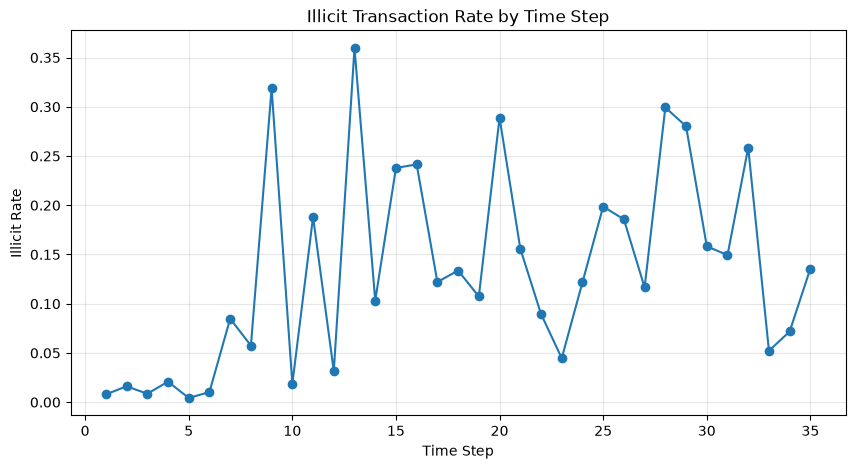

In [5]:
plt.figure(figsize=(10, 5))

plt.plot(
    time_summary.index,
    time_summary["illicit_rate"],
    marker="o"
)

plt.xlabel("Time Step")
plt.ylabel("Illicit Rate")
plt.title("Illicit Transaction Rate by Time Step")
plt.grid(alpha=0.3)
plt.show()

# Variation in illicit prevalence across time steps motivates
# chronological rather than random validation.

## 3. Model Development and Experiments

### V0: Logistic Regression Baseline

**Purpose:** Establish a simple linear baseline before introducing more complex
models.

**Features:** 165 anonymised transaction features.

**Class imbalance:** Balanced class weights are used because illicit
transactions represent a minority of labelled observations.

Logistic Regression is evaluated using the same three expanding-window temporal
folds used throughout model development. This provides a simple benchmark for
assessing whether nonlinear models provide additional predictive value.

In [70]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import pandas as pd

def evaluate_logistic_temporal_split(train_end, val_start, val_end):
    train_fold = labelled[labelled["time_step"] <= train_end].copy()
    val_fold = labelled[
        (labelled["time_step"] >= val_start) &
        (labelled["time_step"] <= val_end)
    ].copy()

    X_tr = train_fold[feature_cols]
    y_tr = train_fold["label"].astype(int)

    X_va = val_fold[feature_cols]
    y_va = val_fold["label"].astype(int)

    model = LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )

    model.fit(X_tr, y_tr)
    pred = model.predict_proba(X_va)[:, 1]

    auc = roc_auc_score(y_va, pred)

    return {
        "train_end": train_end,
        "val_start": val_start,
        "val_end": val_end,
        "n_train": len(train_fold),
        "n_val": len(val_fold),
        "train_illicit_rate": y_tr.mean(),
        "val_illicit_rate": y_va.mean(),
        "auc": auc
    }

In [71]:
folds = [
    (14, 15, 21),
    (21, 22, 28),
    (28, 29, 35)
]

lr_results = []

for train_end, val_start, val_end in folds:
    result = evaluate_logistic_temporal_split(
        train_end, val_start, val_end
    )
    lr_results.append(result)

lr_results_df = pd.DataFrame(lr_results)

display(lr_results_df)

print("Mean AUC:", lr_results_df["auc"].mean())
print("Std AUC:", lr_results_df["auc"].std())
print("Min AUC:", lr_results_df["auc"].min())

,train_end,val_start,val_end,n_train,n_val,train_illicit_rate,val_illicit_rate,auc
0,14,15,21,14896,4634,0.067468,0.186880,0.958681
1,21,22,28,19530,5677,0.095801,0.118196,0.911408
2,28,29,35,25207,6028,0.100845,0.182814,0.927815


Mean AUC: 0.9326348939643645
Std AUC: 0.02400235772889404
Min AUC: 0.9114082475098436


#### V0 Temporal Validation Results

| Fold | Training Period | Validation Period | ROC-AUC |
|---|---|---|---:|
| 1 | 1–14 | 15–21 | 0.9587 |
| 2 | 1–21 | 22–28 | 0.9114 |
| 3 | 1–28 | 29–35 | 0.9278 |

**Mean ROC-AUC:** 0.9326  
**Minimum ROC-AUC:** 0.9114

Performance varies across temporal periods, with Fold 2 producing the
lowest ROC-AUC. This suggests that transactions in time steps 22–28 are
more difficult to generalise to from earlier labelled observations.

These results establish the linear baseline against which subsequent
nonlinear models are compared.

### V1: LightGBM Baseline

**Purpose:** Test whether nonlinear relationships and feature interactions
provide predictive value beyond the Logistic Regression baseline.

**Features:** The same 165 anonymised transaction features used in V0.

**Model specification:**
- 500 boosting iterations
- learning rate = 0.05
- 31 leaves
- random seed = 42

A relatively simple LightGBM configuration is used before introducing graph
features or additional weighting strategies. The model is evaluated using the
same three expanding-window temporal folds as V0.

In [72]:
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

In [73]:
print(feature_cols)

print("\nNumber of features:", len(feature_cols))

print("\nSuspicious columns:")
print([c for c in feature_cols 
       if c in ["label", "txId", "time_step", "index"]])

['feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5', 'feat_6', 'feat_7', 'feat_8', 'feat_9', 'feat_10', 'feat_11', 'feat_12', 'feat_13', 'feat_14', 'feat_15', 'feat_16', 'feat_17', 'feat_18', 'feat_19', 'feat_20', 'feat_21', 'feat_22', 'feat_23', 'feat_24', 'feat_25', 'feat_26', 'feat_27', 'feat_28', 'feat_29', 'feat_30', 'feat_31', 'feat_32', 'feat_33', 'feat_34', 'feat_35', 'feat_36', 'feat_37', 'feat_38', 'feat_39', 'feat_40', 'feat_41', 'feat_42', 'feat_43', 'feat_44', 'feat_45', 'feat_46', 'feat_47', 'feat_48', 'feat_49', 'feat_50', 'feat_51', 'feat_52', 'feat_53', 'feat_54', 'feat_55', 'feat_56', 'feat_57', 'feat_58', 'feat_59', 'feat_60', 'feat_61', 'feat_62', 'feat_63', 'feat_64', 'feat_65', 'feat_66', 'feat_67', 'feat_68', 'feat_69', 'feat_70', 'feat_71', 'feat_72', 'feat_73', 'feat_74', 'feat_75', 'feat_76', 'feat_77', 'feat_78', 'feat_79', 'feat_80', 'feat_81', 'feat_82', 'feat_83', 'feat_84', 'feat_85', 'feat_86', 'feat_87', 'feat_88', 'feat_89', 'feat_90', 'feat_91', 'feat_9

In [74]:
# Evaluate LightGBM using expanding-window temporal validation

def evaluate_temporal_split(train_end, val_start, val_end):
    
    train_fold = labelled[
        labelled["time_step"] <= train_end
    ].copy()
    
    val_fold = labelled[
        (labelled["time_step"] >= val_start) &
        (labelled["time_step"] <= val_end)
    ].copy()

    X_tr = train_fold[feature_cols]
    y_tr = train_fold["label"].astype(int)

    X_va = val_fold[feature_cols]
    y_va = val_fold["label"].astype(int)

    model = LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42,
        verbosity=-1
    )

    model.fit(X_tr, y_tr)

    pred = model.predict_proba(X_va)[:, 1]
    auc = roc_auc_score(y_va, pred)

    return {
        "train_end": train_end,
        "val_start": val_start,
        "val_end": val_end,
        "n_train": len(train_fold),
        "n_val": len(val_fold),
        "train_illicit_rate": y_tr.mean(),
        "val_illicit_rate": y_va.mean(),
        "auc": auc
    }

In [75]:
results = []

for train_end, val_start, val_end in folds:
    result = evaluate_temporal_split(
        train_end,
        val_start,
        val_end
    )
    
    results.append(result)

cv_results = pd.DataFrame(results)

display(cv_results) 

,train_end,val_start,val_end,n_train,n_val,train_illicit_rate,val_illicit_rate,auc
0,14,15,21,14896,4634,0.067468,0.186880,0.991821
1,21,22,28,19530,5677,0.095801,0.118196,0.942002
2,28,29,35,25207,6028,0.100845,0.182814,0.996813


In [76]:
print("Mean AUC:", cv_results["auc"].mean())
print("Std AUC:", cv_results["auc"].std())
print("Min AUC:", cv_results["auc"].min())

Mean AUC: 0.9768785929158246
Std AUC: 0.0303070248008316
Min AUC: 0.9420019374663964


#### V1 Temporal Validation Results

| Fold | Training Period | Validation Period | ROC-AUC |
|---|---|---|---:|
| 1 | 1–14 | 15–21 | 0.9918 |
| 2 | 1–21 | 22–28 | 0.9420 |
| 3 | 1–28 | 29–35 | 0.9968 |

**Mean ROC-AUC:** 0.9769  
**Minimum ROC-AUC:** 0.9420

Performance varies substantially across temporal folds, with Fold 2 being
considerably more difficult than Folds 1 and 3. Therefore, subsequent
experiments will be evaluated using the same temporal folds rather than
optimising only for the latest holdout period.

### V2 — LightGBM with Graph Degree Features

**Purpose:** Evaluate whether transaction-network structure provides predictive
information beyond the 165 anonymised transaction features used in V1.

The supplied directed graph represents payment flows between Bitcoin
transactions. An edge from transaction A to transaction B indicates that an
output created by A is subsequently spent as an input to B. Based on this
structure, three node-level connectivity features are constructed:

- `in_degree`: number of incoming connections from predecessor transactions;
- `out_degree`: number of outgoing connections to successor transactions;
- `total_degree`: total incoming and outgoing connectivity.

These measures capture transaction connectivity in the supplied graph rather
than the raw number of Bitcoin inputs or outputs.

**Experimental design:** The LightGBM specification and three expanding-window
temporal validation folds are kept identical to V1. Therefore, differences
between V1 and V2 can be attributed to the addition of graph degree features
rather than changes in model specification or validation design.

No transaction labels are used to construct the graph features, avoiding
label leakage during temporal validation.

In [77]:
# Count incoming connections for each transaction
in_degree = (
    edges.groupby("txId2")
    .size()
    .rename("in_degree")
)

# Count outgoing connections for each transaction
out_degree = (
    edges.groupby("txId1")
    .size()
    .rename("out_degree")
)

# Combine graph features
graph_features = pd.concat(
    [in_degree, out_degree],
    axis=1
).fillna(0)

# Total graph connectivity
graph_features["total_degree"] = (
    graph_features["in_degree"]
    + graph_features["out_degree"]
)

graph_features.head()

,in_degree,out_degree,total_degree
1076,1.0,1.0,2.0
3181,1.0,112.0,113.0
3321,1.0,0.0,1.0
5473,1.0,28.0,29.0
6415,1.0,1.0,2.0


In [78]:
train_graph = train.merge(
    graph_features,
    left_on="txId",
    right_index=True,
    how="left"
)

test_graph = test.merge(
    graph_features,
    left_on="txId",
    right_index=True,
    how="left"
)

degree_cols = [
    "in_degree",
    "out_degree",
    "total_degree"
]

# Transactions with no observed connections receive degree 0
train_graph[degree_cols] = train_graph[degree_cols].fillna(0)
test_graph[degree_cols] = test_graph[degree_cols].fillna(0)

train_graph[degree_cols].describe()

,in_degree,out_degree,total_degree
count,141772.000000,141772.000000,141772.000000
mean,1.151102,1.151102,2.302204
std,3.568221,1.960910,4.045061
min,0.000000,0.000000,1.000000
25%,0.000000,1.000000,1.000000
50%,1.000000,1.000000,2.000000
75%,1.000000,1.000000,2.000000
max,284.000000,472.000000,473.000000


In [79]:
labelled_graph = train_graph[
    train_graph["label"].notna()
].copy()

feature_cols_v2 = feature_cols + degree_cols

print("V1 number of features:", len(feature_cols))
print("V2 number of features:", len(feature_cols_v2))

print("\nV2 graph features:")
print(degree_cols)

V1 number of features: 165
V2 number of features: 168

V2 graph features:
['in_degree', 'out_degree', 'total_degree']


In [80]:
def evaluate_lgbm_temporal_cv(data, features, folds):
    results = []

    for train_end, val_start, val_end in folds:

        train_fold = data[
            data["time_step"] <= train_end
        ].copy()

        val_fold = data[
            (data["time_step"] >= val_start) &
            (data["time_step"] <= val_end)
        ].copy()

        X_tr = train_fold[features]
        y_tr = train_fold["label"].astype(int)

        X_va = val_fold[features]
        y_va = val_fold["label"].astype(int)

        model = LGBMClassifier(
            n_estimators=500,
            learning_rate=0.05,
            num_leaves=31,
            random_state=42,
            verbosity=-1
        )

        model.fit(X_tr, y_tr)

        pred = model.predict_proba(X_va)[:, 1]

        auc = roc_auc_score(y_va, pred)

        results.append({
            "train_end": train_end,
            "val_start": val_start,
            "val_end": val_end,
            "n_train": len(train_fold),
            "n_val": len(val_fold),
            "train_illicit_rate": y_tr.mean(),
            "val_illicit_rate": y_va.mean(),
            "auc": auc
        })

    return pd.DataFrame(results)

In [81]:
v2_results = evaluate_lgbm_temporal_cv(
    data=labelled_graph,
    features=feature_cols_v2,
    folds=folds
)

display(v2_results)

print("Mean AUC:", v2_results["auc"].mean())
print("Std AUC:", v2_results["auc"].std())
print("Min AUC:", v2_results["auc"].min())

,train_end,val_start,val_end,n_train,n_val,train_illicit_rate,val_illicit_rate,auc
0,14,15,21,14896,4634,0.067468,0.186880,0.991457
1,21,22,28,19530,5677,0.095801,0.118196,0.945128
2,28,29,35,25207,6028,0.100845,0.182814,0.996755


Mean AUC: 0.9777799844701871
Std AUC: 0.02840140722276142
Min AUC: 0.9451278436070456


In [82]:
results_df = pd.DataFrame(results)

comparison_v1_v2 = pd.DataFrame({
    "Fold": ["Fold 1", "Fold 2", "Fold 3"],
    "V1_LightGBM": results_df["auc"].values,
    "V2_LightGBM_Degree": v2_results["auc"].values
})

comparison_v1_v2["Difference"] = (
    comparison_v1_v2["V2_LightGBM_Degree"]
    - comparison_v1_v2["V1_LightGBM"]
)

display(comparison_v1_v2)

print("V1 Mean AUC:", results_df["auc"].mean())
print("V2 Mean AUC:", v2_results["auc"].mean())

print(
    "Mean AUC Difference:",
    v2_results["auc"].mean()
    - results_df["auc"].mean()
)

,Fold,V1_LightGBM,V2_LightGBM_Degree,Difference
0,Fold 1,0.991821,0.991457,-0.000364
1,Fold 2,0.942002,0.945128,0.003126
2,Fold 3,0.996813,0.996755,-0.000058


V1 Mean AUC: 0.9768785929158246
V2 Mean AUC: 0.9777799844701871
Mean AUC Difference: 0.0009013915543625295


#### V2 Results and Interpretation

| Fold | V1: LightGBM | V2: LightGBM + Degree | Difference |
|---|---:|---:|---:|
| 1 | 0.9918 | 0.9915 | -0.0004 |
| 2 | 0.9420 | 0.9451 | +0.0031 |
| 3 | 0.9968 | 0.9968 | -0.0001 |
| **Mean** | **0.9769** | **0.9778** | **+0.0009** |

Adding the three graph connectivity features produced a small increase in
mean temporal ROC-AUC from 0.9769 to 0.9778. Performance was effectively
unchanged in Folds 1 and 3, while Fold 2, the weakest validation period for
V1, improved from 0.9420 to 0.9451.

Overall, simple node degree provides limited but positive incremental
predictive information beyond the 165 anonymised transaction features.
The modest improvement also suggests that degree alone does not fully
capture potentially useful information contained in the transaction graph.

The graph features were derived from the supplied graph topology without
using transaction labels. Graph structure is treated as observable
information, while the expanding-window temporal folds determine which
labelled observations are available for model training and validation.

**Decision:** Retain V2 as the current best model based on mean temporal
ROC-AUC and use it as the first Kaggle submission benchmark. Further
experiments will investigate richer graph-based features.

In [83]:
duplicate_edges = edges.duplicated(
    subset=["txId1", "txId2"]
).sum()

print("Duplicate directed edges:", duplicate_edges)

Duplicate directed edges: 0


### V3 — LightGBM with Neighbourhood Connectivity Features

**Purpose:** Evaluate whether the local graph environment of a transaction
provides predictive information beyond its own connectivity.

V2 represented each transaction using its in-degree, out-degree and total
degree. However, these features describe only the focal transaction and do
not characterise the transactions to which it is connected.

V3 therefore augments V2 with one-hop neighbourhood statistics. For each
transaction, the degree characteristics of predecessor and successor
transactions are aggregated separately, preserving the direction of the
payment-flow graph.

The LightGBM specification and expanding-window temporal validation framework
are kept unchanged from V2 so that any performance difference can be
attributed to the additional neighbourhood features.

In [84]:
# Add total degree to each edge endpoint

edges_v3 = edges.copy()

# Degree of predecessor transaction (txId1)
edges_v3 = edges_v3.merge(
    graph_features[["total_degree"]],
    left_on="txId1",
    right_index=True,
    how="left"
).rename(columns={
    "total_degree": "predecessor_degree"
})

# Degree of successor transaction (txId2)
edges_v3 = edges_v3.merge(
    graph_features[["total_degree"]],
    left_on="txId2",
    right_index=True,
    how="left"
).rename(columns={
    "total_degree": "successor_degree"
})

In [85]:
predecessor_stats = (
    edges_v3.groupby("txId2")["predecessor_degree"]
    .agg(["mean", "max"])
    .rename(columns={
        "mean": "pred_degree_mean",
        "max": "pred_degree_max"
    })
)

In [86]:
successor_stats = (
    edges_v3.groupby("txId1")["successor_degree"]
    .agg(["mean", "max"])
    .rename(columns={
        "mean": "succ_degree_mean",
        "max": "succ_degree_max"
    })
)

In [87]:
neighbour_features = pd.concat(
    [predecessor_stats, successor_stats],
    axis=1
).fillna(0)

display(neighbour_features.head())
neighbour_features.describe()

,pred_degree_mean,pred_degree_max,succ_degree_mean,succ_degree_max
1076,2.0,2.0,31.0000,31.0
3181,1.0,1.0,3.9375,47.0
3321,2.0,2.0,0.0000,0.0
5473,16.0,16.0,4.7500,54.0
6415,2.0,2.0,1.0000,1.0


,pred_degree_mean,pred_degree_max,succ_degree_mean,succ_degree_max
count,203769.000000,203769.000000,203769.000000,203769.000000
mean,4.096977,4.782106,12.241859,15.918805
std,22.030332,26.497519,27.420968,35.694751
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.500000,2.000000
50%,2.000000,2.000000,2.000000,2.000000
75%,3.000000,3.000000,7.000000,9.000000
max,473.000000,473.000000,284.000000,473.000000


In [88]:
train_v3 = train_graph.merge(
    neighbour_features,
    left_on="txId",
    right_index=True,
    how="left"
)

test_v3 = test_graph.merge(
    neighbour_features,
    left_on="txId",
    right_index=True,
    how="left"
)

neighbour_cols = [
    "pred_degree_mean",
    "pred_degree_max",
    "succ_degree_mean",
    "succ_degree_max"
]

train_v3[neighbour_cols] = train_v3[neighbour_cols].fillna(0)
test_v3[neighbour_cols] = test_v3[neighbour_cols].fillna(0)

feature_cols_v3 = feature_cols_v2 + neighbour_cols

print("V2 features:", len(feature_cols_v2))
print("V3 features:", len(feature_cols_v3))

V2 features: 168
V3 features: 172


In [89]:
labelled_v3 = train_v3[train_v3["label"].notna()].copy()

print("Labelled observations:", len(labelled_v3))
print("Number of V3 features:", len(feature_cols_v3))

Labelled observations: 31235
Number of V3 features: 172


In [90]:
v3_results = evaluate_lgbm_temporal_cv(
    data=labelled_v3,
    features=feature_cols_v3,
    folds=folds
)

display(v3_results)

,train_end,val_start,val_end,n_train,n_val,train_illicit_rate,val_illicit_rate,auc
0,14,15,21,14896,4634,0.067468,0.186880,0.992626
1,21,22,28,19530,5677,0.095801,0.118196,0.949702
2,28,29,35,25207,6028,0.100845,0.182814,0.996973


In [91]:
print("V3 mean AUC:", v3_results["auc"].mean())
print("V3 std AUC:", v3_results["auc"].std())
print("V3 min AUC:", v3_results["auc"].min())

V3 mean AUC: 0.9797668031687891
V3 std AUC: 0.02612761167275902
V3 min AUC: 0.9497017885541821


In [92]:
v1_v2_v3_comparison = pd.DataFrame({
    "Fold": [1, 2, 3],
    "V1_LightGBM": results_df["auc"].values,
    "V2_Degree": v2_results["auc"].values,
    "V3_Neighbourhood": v3_results["auc"].values
})

# Changes between successive versions
v1_v2_v3_comparison["V2_minus_V1"] = (
    v1_v2_v3_comparison["V2_Degree"]
    - v1_v2_v3_comparison["V1_LightGBM"]
)

v1_v2_v3_comparison["V3_minus_V2"] = (
    v1_v2_v3_comparison["V3_Neighbourhood"]
    - v1_v2_v3_comparison["V2_Degree"]
)

display(v1_v2_v3_comparison)

,Fold,V1_LightGBM,V2_Degree,V3_Neighbourhood,V2_minus_V1,V3_minus_V2
0,1,0.991821,0.991457,0.992626,-0.000364,0.001169
1,2,0.942002,0.945128,0.949702,0.003126,0.004574
2,3,0.996813,0.996755,0.996973,-0.000058,0.000217


In [93]:
summary = pd.DataFrame({
    "Model": [
        "V1 - LightGBM",
        "V2 - + Degree",
        "V3 - + Neighbourhood"
    ],
    "Mean_AUC": [
        results_df["auc"].mean(),
        v2_results["auc"].mean(),
        v3_results["auc"].mean()
    ],
    "Min_AUC": [
        results_df["auc"].min(),
        v2_results["auc"].min(),
        v3_results["auc"].min()
    ],
    "Std_AUC": [
        results_df["auc"].std(),
        v2_results["auc"].std(),
        v3_results["auc"].std()
    ]
})

display(summary)

,Model,Mean_AUC,Min_AUC,Std_AUC
0,V1 - LightGBM,0.976879,0.942002,0.030307
1,V2 - + Degree,0.977780,0.945128,0.028401
2,V3 - + Neighbourhood,0.979767,0.949702,0.026128


#### V3 Results and Interpretation

| Fold | V1: LightGBM | V2: + Degree | V3: + Neighbourhood |
|---|---:|---:|---:|
| 1 | 0.9918 | 0.9915 | **0.9926** |
| 2 | 0.9420 | 0.9451 | **0.9497** |
| 3 | 0.9968 | 0.9968 | **0.9970** |
| **Mean** | **0.9769** | **0.9778** | **0.9798** |

Adding one-hop neighbourhood connectivity features increased mean temporal
ROC-AUC from 0.9778 in V2 to 0.9798 in V3. Unlike the V1-to-V2 change,
V3 improved performance across all three temporal validation folds.

The largest improvement occurred in Fold 2, where ROC-AUC increased from
0.9451 to 0.9497. This fold had consistently produced the lowest performance
in earlier experiments, suggesting that neighbourhood connectivity provides
additional information during the more difficult validation period.

The results indicate that graph information beyond a transaction's own
degree provides incremental predictive value. In particular, the connectivity
of predecessor and successor transactions appears to contain information not
fully captured by the original transaction features or focal-node degree.

**Decision:** Retain V3 as the current highest-performing model under
expanding-window temporal validation and evaluate it on the Kaggle test set.

## Feature Diagnostics and Selection

### Motivation

V1–V3 progressively expanded the model by combining the original anonymised
transaction attributes with graph-based connectivity and neighbourhood features.

Before introducing richer graph representations, feature diagnostics are
conducted to assess whether the current V3 feature set contains variables that
provide limited information or are highly redundant.

Three diagnostics are considered:

1. **Variance:** Features with very low variance change little across transactions
   and may provide limited discriminatory information.

2. **Correlation:** Highly correlated features may contain overlapping information.
   Removing redundant features may reduce unnecessary model complexity.

3. **Model-based importance:** LightGBM feature importance is used to identify
   variables that contribute little to the fitted model.

These diagnostics are used to construct a reduced V4 feature set. V4 is then
evaluated using the same LightGBM specification and expanding-window temporal
validation framework as V3 to determine whether feature reduction improves
out-of-time generalisation.

In [30]:
# Feature variance diagnostic on labelled training data

X_diag = labelled_v3[feature_cols_v3]

feature_variance = X_diag.var().sort_values()

variance_df = pd.DataFrame({
    "feature": feature_variance.index,
    "variance": feature_variance.values
})

display(variance_df.head(20))

print("Total features:", len(feature_cols_v3))
print("Zero-variance features:", (feature_variance == 0).sum())
print("Near-zero variance (< 1e-6):", (feature_variance < 1e-6).sum())

,feature,variance
0,feat_15,0.000079
1,feat_18,0.113389
2,feat_19,0.195783
3,feat_142,0.201951
4,feat_145,0.235373
5,feat_106,0.237414
6,feat_8,0.243852
7,feat_11,0.251914
8,feat_144,0.255335
9,feat_109,0.283000


Total features: 172
Zero-variance features: 0
Near-zero variance (< 1e-6): 0


### Variance Diagnostic

All 172 features have non-zero variance, and no features have near-zero variance below the 1e-6 threshold.

Therefore, no features are removed based on variance. This suggests that all features exhibit sufficient variation across the labelled training observations to potentially provide discriminatory information.

In [31]:
# Pairwise correlation among V3 features

corr_matrix = X_diag.corr().abs()

# Keep only upper triangle so each pair is counted once
upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

high_corr_pairs = (
    high_corr_pairs[
        high_corr_pairs["correlation"] >= 0.95
    ]
    .sort_values("correlation", ascending=False)
)

print(
    "Number of feature pairs with |correlation| >= 0.95:",
    len(high_corr_pairs)
)

display(high_corr_pairs.head(30))

Number of feature pairs with |correlation| >= 0.95: 91


,feature_1,feature_2,correlation
3985,feat_24,feat_30,1.000000
10040,feat_59,feat_65,1.000000
3812,feat_23,feat_29,1.000000
701,feat_5,feat_14,1.000000
10213,feat_60,feat_66,1.000000
10386,feat_61,feat_67,1.000000
4158,feat_25,feat_31,1.000000
3639,feat_22,feat_28,1.000000
9867,feat_58,feat_64,0.999989
4331,feat_26,feat_32,0.999160


### Correlation Diagnostic

The correlation analysis identified 91 feature pairs with an absolute Pearson
correlation of at least 0.95. Several pairs exhibit near-perfect or perfect
correlation, indicating substantial redundancy within the V3 feature set.

For example, `feat_24` and `feat_30`, `feat_59` and `feat_65`, and several other
pairs have correlations of approximately 1.0.

However, the number of highly correlated pairs does not directly correspond to
the number of redundant features, as individual features may appear in multiple
correlated pairs. Rather than removing both variables in each pair, one feature
from each highly correlated relationship can be considered for removal while
retaining the other.

Whether this reduction improves predictive performance will be evaluated using
the same temporal validation framework as V3.

In [32]:
# Fit V3 on all labelled observations for feature-importance diagnostics

diagnostic_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

diagnostic_model.fit(
    labelled_v3[feature_cols_v3],
    labelled_v3["label"].astype(int)
)

v3_importance = pd.DataFrame({
    "feature": feature_cols_v3,
    "importance": diagnostic_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

display(v3_importance.head(30))

print(
    "Features with zero importance:",
    (v3_importance["importance"] == 0).sum()
)

display(
    v3_importance[
        v3_importance["importance"] == 0
    ]
)

,feature,importance
0,feat_2,1001
1,feat_53,533
2,feat_52,333
3,feat_138,324
4,feat_88,299
5,feat_106,296
6,feat_55,255
7,feat_58,253
8,feat_3,249
9,feat_16,234


Features with zero importance: 7


,feature,importance
165,feat_39,0
166,feat_38,0
167,feat_15,0
168,feat_14,0
169,feat_7,0
170,feat_36,0
171,feat_87,0


### Model-Based Feature Importance

Feature importance from a LightGBM model fitted using the full V3 feature set
shows that predictive contribution is concentrated among a subset of features.

Seven features (`feat_7`, `feat_14`, `feat_15`, `feat_36`, `feat_38`,
`feat_39`, and `feat_87`) have zero importance, indicating that they were not
used in any split by the fitted diagnostic model.

Together with the substantial correlation observed among the V3 features,
these results suggest that the current feature space contains some redundant
or weakly contributing variables. A reduced feature set is therefore evaluated
in V4.

## V4: Reduced Feature Model

### Feature Selection Strategy

Based on the preceding diagnostics, V4 evaluates whether removing redundant
and weakly contributing features improves temporal generalisation.

The reduction follows two rules:

1. Features with zero LightGBM importance are removed.
2. For each pair of features with absolute correlation of at least 0.95,
   the feature with lower LightGBM importance is removed. Where importance
   is equal, one feature is retained deterministically.

This approach avoids removing features solely because they are correlated:
model-based importance is used to determine which member of a highly
correlated pair to retain.

The resulting reduced feature set is evaluated using the same LightGBM
hyperparameters and expanding-window temporal validation folds as V3.

In [33]:
# Map each feature to its V3 LightGBM importance
importance_map = dict(
    zip(v3_importance["feature"], v3_importance["importance"])
)

# 1. Zero-importance features
zero_importance_features = set(
    v3_importance.loc[
        v3_importance["importance"] == 0,
        "feature"
    ]
)

# 2. For each highly correlated pair, remove the less important feature
correlated_features_to_drop = set()

for _, row in high_corr_pairs.iterrows():
    f1 = row["feature_1"]
    f2 = row["feature_2"]

    imp1 = importance_map[f1]
    imp2 = importance_map[f2]

    if imp1 < imp2:
        correlated_features_to_drop.add(f1)
    elif imp2 < imp1:
        correlated_features_to_drop.add(f2)
    else:
        # Deterministic tie-break: retain f1, remove f2
        correlated_features_to_drop.add(f2)

# Combine both criteria
features_to_drop_v4 = (
    zero_importance_features |
    correlated_features_to_drop
)

feature_cols_v4 = [
    f for f in feature_cols_v3
    if f not in features_to_drop_v4
]

print("V3 features:", len(feature_cols_v3))
print("Zero-importance features:", len(zero_importance_features))
print(
    "Features selected for removal due to high correlation:",
    len(correlated_features_to_drop)
)
print("Unique features removed:", len(features_to_drop_v4))
print("V4 features retained:", len(feature_cols_v4))

print("\nFeatures removed:")
print(sorted(features_to_drop_v4))

V3 features: 172
Zero-importance features: 7
Features selected for removal due to high correlation: 62
Unique features removed: 66
V4 features retained: 106

Features removed:
['feat_1', 'feat_103', 'feat_105', 'feat_11', 'feat_111', 'feat_116', 'feat_12', 'feat_122', 'feat_129', 'feat_133', 'feat_135', 'feat_136', 'feat_14', 'feat_141', 'feat_147', 'feat_15', 'feat_153', 'feat_159', 'feat_165', 'feat_21', 'feat_27', 'feat_28', 'feat_29', 'feat_30', 'feat_31', 'feat_32', 'feat_33', 'feat_35', 'feat_36', 'feat_37', 'feat_38', 'feat_39', 'feat_40', 'feat_43', 'feat_44', 'feat_45', 'feat_47', 'feat_49', 'feat_50', 'feat_57', 'feat_6', 'feat_60', 'feat_61', 'feat_63', 'feat_64', 'feat_65', 'feat_66', 'feat_67', 'feat_68', 'feat_69', 'feat_7', 'feat_71', 'feat_73', 'feat_75', 'feat_77', 'feat_78', 'feat_81', 'feat_82', 'feat_84', 'feat_85', 'feat_86', 'feat_87', 'feat_9', 'feat_93', 'feat_97', 'feat_99']


In [34]:
v4_results = evaluate_lgbm_temporal_cv(
    data=labelled_v3,
    features=feature_cols_v4,
    folds=folds
)

display(v4_results)

print(f"V4 Mean AUC: {v4_results['auc'].mean():.6f}")
print(f"V4 Std AUC:  {v4_results['auc'].std():.6f}")

,train_end,val_start,val_end,n_train,n_val,train_illicit_rate,val_illicit_rate,auc
0,14,15,21,14896,4634,0.067468,0.186880,0.992018
1,21,22,28,19530,5677,0.095801,0.118196,0.942195
2,28,29,35,25207,6028,0.100845,0.182814,0.997354


V4 Mean AUC: 0.977189
V4 Std AUC:  0.030423


In [35]:
v3_v4_comparison = pd.DataFrame({
    "Fold": [1, 2, 3],
    "V3 AUC": v3_results["auc"].values,
    "V4 AUC": v4_results["auc"].values
})

v3_v4_comparison["Difference"] = (
    v3_v4_comparison["V4 AUC"]
    - v3_v4_comparison["V3 AUC"]
)

display(v3_v4_comparison)

print(f"V3 Mean AUC: {v3_results['auc'].mean():.6f}")
print(f"V4 Mean AUC: {v4_results['auc'].mean():.6f}")
print(
    f"Mean Difference: "
    f"{v4_results['auc'].mean() - v3_results['auc'].mean():+.6f}"
)

,Fold,V3 AUC,V4 AUC,Difference
0,1,0.992626,0.992018,-0.000608
1,2,0.949702,0.942195,-0.007507
2,3,0.996973,0.997354,0.000381


V3 Mean AUC: 0.979767
V4 Mean AUC: 0.977189
Mean Difference: -0.002578


### V4 Results and Interpretation

V4 reduced the feature set from 172 to 106 features by removing zero-importance
features and the lower-importance member of highly correlated feature pairs.

Under expanding-window temporal validation, mean ROC-AUC decreased slightly from
0.979767 in V3 to 0.977189 in V4. The largest deterioration occurred in Fold 2,
where ROC-AUC decreased from 0.949702 to 0.942195, while Fold 3 improved slightly.

However, V4 achieved a public Kaggle ROC-AUC of 0.94871, compared with 0.94749
for V3. Thus, despite its slightly weaker historical temporal validation
performance, the reduced model performed marginally better on the public leaderboard subset while using approximately 38% fewer features.

The conflicting validation and leaderboard results suggest that feature
selection involves a trade-off rather than providing an unambiguous improvement.
The reduced feature set may remove some useful historical signal while also
reducing redundancy that does not generalise to later periods.

Since the public leaderboard represents only 30% of the test data, the small
improvement should not be interpreted as conclusive evidence that V4 is superior.
Nevertheless, the result suggested that feature redundancy was relevant and motivated the later use of feature importance to restrict neighbour-attribute aggregation to a targeted subset of original features.

Because the feature-selection rule was derived using importance estimated from the full labelled training set, the V4 temporal-validation result is exploratory rather than fully nested and may contain some feature-selection optimism.

## V5: Richer One-Hop Graph Features

### Motivation

V2 and V3 showed that graph structure provides additional predictive information
beyond the anonymised transaction attributes. V2 captured the connectivity of the
focal transaction, while V3 extended this representation to the connectivity of
its immediate predecessors and successors.

However, these graph features describe only **how connected neighbouring
transactions are**. They do not describe the underlying transaction characteristics
of those neighbours.

V5 therefore extends the one-hop graph representation by aggregating selected
transaction attributes from directly connected transactions.

Two variants are considered:

- **V5.1:** richer neighbourhood attributes added to the full V3 feature set.
- **V5.2:** the same neighbourhood attributes added to the reduced V4 feature set.

This design separates the effect of richer graph information from the effect of
feature selection.

### V5.1: Neighbour Attributes with Full Feature Set

V5.1 uses V3 as its baseline and adds transaction-attribute information from each
transaction's immediate predecessors and successors.

Aggregating all 165 anonymised transaction features would substantially increase
dimensionality and may introduce additional redundancy. Instead, the 10 most
important original transaction features from the V3 LightGBM importance analysis
are selected.

For each selected feature, two new variables are constructed:

- the mean feature value among the transaction's immediate predecessors; and
- the mean feature value among the transaction's immediate successors.

This produces 20 additional neighbourhood features.

All LightGBM hyperparameters and temporal validation folds are kept unchanged from
V3. Therefore, the comparison between V3 and V5.1 isolates the incremental value
of richer one-hop neighbourhood information.

In [36]:
# Select the 10 most important original transaction features
top_features_v5 = (
    v3_importance[
        v3_importance["feature"].str.startswith("feat_")
    ]
    .head(10)["feature"]
    .tolist()
)

print("Top 10 transaction features selected for V5:")
for i, feature in enumerate(top_features_v5, start=1):
    print(f"{i}. {feature}")

Top 10 transaction features selected for V5:
1. feat_2
2. feat_53
3. feat_52
4. feat_138
5. feat_88
6. feat_106
7. feat_55
8. feat_58
9. feat_3
10. feat_16


The top 10 original transaction features are selected using feature importance
from the V3 LightGBM model. Restricting neighbour aggregation to these features
provides a targeted representation of neighbouring transaction characteristics
without aggregating all 165 anonymised attributes.

### Neighbour Attribute Construction

The transaction graph is directed. An edge from transaction A to transaction B
indicates that an output of A is subsequently spent as an input to B.

For a focal transaction X:

- **Predecessors** are transactions with edges pointing into X.
- **Successors** are transactions that X points to.

For each of the 10 selected transaction features, the mean value is calculated
separately across X's predecessors and successors.

Predecessor and successor attributes are kept separate because incoming and
outgoing relationships may capture different transaction-flow behaviour.

No transaction labels are used in constructing these features. The aggregation
uses only transaction attributes and graph connectivity.

This constitutes label-free transductive feature engineering: observable transaction attributes and graph connectivity from the supplied dataset are used to construct neighbourhood features, but no test labels are used.

In [37]:
# Combine train and test transaction attributes so graph neighbours can be
# matched regardless of whether they belong to the training or test set.

all_transactions_v5 = pd.concat(
    [
        train[["txId"] + top_features_v5],
        test[["txId"] + top_features_v5]
    ],
    ignore_index=True
).drop_duplicates("txId")

print("Transactions available for neighbour aggregation:",
      len(all_transactions_v5))

Transactions available for neighbour aggregation: 157101


In [38]:
# -----------------------------
# Predecessor feature aggregates
# -----------------------------

# txId1 = predecessor
# txId2 = focal transaction
pred_edges_v5 = edges.merge(
    all_transactions_v5,
    left_on="txId1",
    right_on="txId",
    how="left"
)

pred_attribute_stats = (
    pred_edges_v5
    .groupby("txId2")[top_features_v5]
    .mean()
)

pred_attribute_stats.columns = [
    f"pred_{feature}_mean"
    for feature in top_features_v5
]

# ---------------------------
# Successor feature aggregates
# ---------------------------

# txId1 = focal transaction
# txId2 = successor
succ_edges_v5 = edges.merge(
    all_transactions_v5,
    left_on="txId2",
    right_on="txId",
    how="left"
)

succ_attribute_stats = (
    succ_edges_v5
    .groupby("txId1")[top_features_v5]
    .mean()
)

succ_attribute_stats.columns = [
    f"succ_{feature}_mean"
    for feature in top_features_v5
]

# Combine predecessor and successor attributes
neighbour_attribute_features = pd.concat(
    [pred_attribute_stats, succ_attribute_stats],
    axis=1
)

print(
    "Number of new neighbour attribute features:",
    neighbour_attribute_features.shape[1]
)

display(neighbour_attribute_features.head())

Number of new neighbour attribute features: 20


,pred_feat_2_mean,pred_feat_53_mean,pred_feat_52_mean,pred_feat_138_mean,pred_feat_88_mean,pred_feat_106_mean,pred_feat_55_mean,pred_feat_58_mean,pred_feat_3_mean,pred_feat_16_mean,succ_feat_2_mean,succ_feat_53_mean,succ_feat_52_mean,succ_feat_138_mean,succ_feat_88_mean,succ_feat_106_mean,succ_feat_55_mean,succ_feat_58_mean,succ_feat_3_mean,succ_feat_16_mean
1076,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3181,-0.210553,4.920559,6.089451,-0.292341,1.782872,-0.177664,5.77278,-0.038820,-1.756361,-0.056878,0.265918,1.243325,1.232302,1.553195,0.028945,-0.177664,1.242239,0.048708,0.532983,0.219533
3321,-0.184668,1.378639,1.830780,0.050953,-0.113308,-0.166550,1.68641,-0.039149,-1.201369,-0.042785,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5473,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.700931,0.835818,0.392460,0.350825,0.125033,1.596344,0.604827,2.055082,1.107401,1.364064
6415,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### V5.1 Feature Set

The 20 neighbour-attribute features are merged with the full V3 representation.

Transactions without a predecessor or successor do not have a corresponding
neighbour aggregate. These missing aggregate values are filled with zero,
consistent with the absence of neighbour information in that direction.

V5.1 therefore retains all 172 V3 features and adds 20 richer neighbourhood
attributes, producing 192 features in total.

In [39]:
# Add richer neighbourhood attributes to the V3 datasets

train_v51 = train_v3.merge(
    neighbour_attribute_features,
    left_on="txId",
    right_index=True,
    how="left"
)

test_v51 = test_v3.merge(
    neighbour_attribute_features,
    left_on="txId",
    right_index=True,
    how="left"
)

v51_new_features = list(neighbour_attribute_features.columns)

# No predecessor/successor -> no neighbour aggregate available
train_v51[v51_new_features] = (
    train_v51[v51_new_features].fillna(0)
)

test_v51[v51_new_features] = (
    test_v51[v51_new_features].fillna(0)
)

feature_cols_v51 = feature_cols_v3 + v51_new_features

labelled_v51 = train_v51[
    train_v51["label"].notna()
].copy()

print("V3 feature count:", len(feature_cols_v3))
print("New V5.1 features:", len(v51_new_features))
print("V5.1 total feature count:", len(feature_cols_v51))

print("Missing values in V5.1 train features:",
      labelled_v51[feature_cols_v51].isna().sum().sum())

print("Missing values in V5.1 test features:",
      test_v51[feature_cols_v51].isna().sum().sum())

V3 feature count: 172
New V5.1 features: 20
V5.1 total feature count: 192
Missing values in V5.1 train features: 0
Missing values in V5.1 test features: 0


### Temporal Validation

V5.1 is evaluated using the same three expanding-window temporal folds and
LightGBM specification used for V1–V4.

Since the model specification and validation periods are unchanged, differences
between V3 and V5.1 can be attributed to the addition of the 20 neighbour
transaction-attribute features.

In [40]:
v51_results = evaluate_lgbm_temporal_cv(
    data=labelled_v51,
    features=feature_cols_v51,
    folds=folds
)

display(v51_results)

print(f"V5.1 Mean AUC: {v51_results['auc'].mean():.6f}")
print(f"V5.1 Std AUC:  {v51_results['auc'].std():.6f}")

,train_end,val_start,val_end,n_train,n_val,train_illicit_rate,val_illicit_rate,auc
0,14,15,21,14896,4634,0.067468,0.186880,0.993035
1,21,22,28,19530,5677,0.095801,0.118196,0.941545
2,28,29,35,25207,6028,0.100845,0.182814,0.996699


V5.1 Mean AUC: 0.977093
V5.1 Std AUC:  0.030840


In [41]:
v3_v51_comparison = pd.DataFrame({
    "Fold": [1, 2, 3],
    "V3 AUC": v3_results["auc"].values,
    "V5.1 AUC": v51_results["auc"].values
})

v3_v51_comparison["Difference"] = (
    v3_v51_comparison["V5.1 AUC"]
    - v3_v51_comparison["V3 AUC"]
)

display(v3_v51_comparison)

print(f"V3 Mean AUC:   {v3_results['auc'].mean():.6f}")
print(f"V5.1 Mean AUC: {v51_results['auc'].mean():.6f}")
print(
    "Mean Difference:",
    f"{v51_results['auc'].mean() - v3_results['auc'].mean():+.6f}"
)

,Fold,V3 AUC,V5.1 AUC,Difference
0,1,0.992626,0.993035,0.000409
1,2,0.949702,0.941545,-0.008157
2,3,0.996973,0.996699,-0.000273


V3 Mean AUC:   0.979767
V5.1 Mean AUC: 0.977093
Mean Difference: -0.002674


### V5.1 Results and Interpretation

Adding richer one-hop neighbourhood attributes decreased mean temporal
ROC-AUC from 0.979767 in V3 to 0.977093 in V5.1. The deterioration was
concentrated primarily in Fold 2, where ROC-AUC decreased from 0.949702
to 0.941545. Fold 1 improved slightly, while Fold 3 remained broadly
unchanged.

Despite the lower historical temporal-validation performance, V5.1 achieved
a public Kaggle ROC-AUC of 0.94963, improving upon V3 (0.94749) and V4
(0.94871).

This suggests that the richer neighbourhood attributes contain incremental
predictive information for the later test period, although their usefulness
is not stable across all historical periods. In particular, the deterioration
in Fold 2 indicates that relationships between neighbouring transaction
attributes may vary over time.

As the public leaderboard represents only 30% of the test data, this
improvement should not be treated as conclusive evidence that V5.1 will
generalise better to the private test set. Nevertheless, the result provides
evidence that transaction attributes from directly connected nodes can
complement structural graph features.

A limitation of this feature-engineering step is that the neighbour attributes were selected using feature importance estimated from the full labelled training set rather than through nested feature selection within each temporal fold. Consequently, subsequent temporal-validation results may contain some feature-selection optimism. This does not affect final test training, where all historical labelled observations are available before prediction.

## V8: LightGBM Hyperparameter Refinement

### Motivation

Experiments V1-V5 used a fixed LightGBM configuration of 500 estimators, a
learning rate of 0.05, and 31 leaves. This allowed earlier comparisons to
isolate the effects of feature engineering rather than model configuration.

The preceding experiments indicate that LightGBM remains the strongest model
family under temporal validation. Before introducing additional feature
engineering, V8 therefore investigates whether the existing LightGBM model can
be improved through controlled hyperparameter refinement.

V3 is used as the primary feature representation for tuning because it achieved
the highest mean temporal-validation ROC-AUC. Hyperparameters are selected using
the same expanding-window temporal-validation framework rather than the public
Kaggle leaderboard.

The search focuses on model complexity, minimum leaf size, feature subsampling,
row subsampling, and regularisation. A relatively small search space is used to
limit computational cost and reduce the risk of overfitting model-development
decisions to the three validation folds.

In [42]:
lgbm_configs = [
    {
        "name": "Baseline",
        "n_estimators": 500,
        "learning_rate": 0.05,
        "num_leaves": 31,
        "min_child_samples": 20,
        "colsample_bytree": 1.0,
        "subsample": 1.0,
        "reg_alpha": 0.0,
        "reg_lambda": 0.0
    },

    {
        "name": "More regularised",
        "n_estimators": 500,
        "learning_rate": 0.05,
        "num_leaves": 31,
        "min_child_samples": 40,
        "colsample_bytree": 0.8,
        "subsample": 0.8,
        "reg_alpha": 0.1,
        "reg_lambda": 0.1
    },

    {
        "name": "Lower complexity",
        "n_estimators": 500,
        "learning_rate": 0.05,
        "num_leaves": 15,
        "min_child_samples": 30,
        "colsample_bytree": 0.9,
        "subsample": 0.9,
        "reg_alpha": 0.1,
        "reg_lambda": 0.1
    },

    {
        "name": "Higher complexity",
        "n_estimators": 500,
        "learning_rate": 0.05,
        "num_leaves": 63,
        "min_child_samples": 30,
        "colsample_bytree": 0.8,
        "subsample": 0.8,
        "reg_alpha": 0.1,
        "reg_lambda": 0.1
    },

    {
        "name": "Slower learning",
        "n_estimators": 800,
        "learning_rate": 0.03,
        "num_leaves": 31,
        "min_child_samples": 30,
        "colsample_bytree": 0.8,
        "subsample": 0.8,
        "reg_alpha": 0.1,
        "reg_lambda": 0.1
    }
]

### Candidate Configurations

Rather than performing an exhaustive hyperparameter search, five targeted
configurations are compared against the existing baseline.

The candidate configurations test whether performance benefits from:

- stronger regularisation and subsampling;
- lower tree complexity;
- higher tree complexity; or
- a lower learning rate with additional boosting iterations.

This targeted approach keeps the experiment interpretable and limits the number
of model-development decisions made using the available validation periods.

In [43]:
def evaluate_lgbm_config(
    data,
    features,
    folds,
    config
):
    fold_aucs = []

    for fold_num, (
        train_end,
        val_start,
        val_end
    ) in enumerate(folds, start=1):

        train_mask = (
            data["time_step"] <= train_end
        )

        val_mask = (
            (data["time_step"] >= val_start)
            & (data["time_step"] <= val_end)
        )

        X_train = data.loc[
            train_mask,
            features
        ]

        y_train = data.loc[
            train_mask,
            "label"
        ].astype(int)

        X_val = data.loc[
            val_mask,
            features
        ]

        y_val = data.loc[
            val_mask,
            "label"
        ].astype(int)

        model = LGBMClassifier(
            n_estimators=config["n_estimators"],
            learning_rate=config["learning_rate"],
            num_leaves=config["num_leaves"],
            min_child_samples=config["min_child_samples"],
            colsample_bytree=config["colsample_bytree"],
            subsample=config["subsample"],
            reg_alpha=config["reg_alpha"],
            reg_lambda=config["reg_lambda"],
            random_state=42,
            verbosity=-1
        )

        model.fit(
            X_train,
            y_train
        )

        val_pred = model.predict_proba(
            X_val
        )[:, 1]

        auc = roc_auc_score(
            y_val,
            val_pred
        )

        fold_aucs.append(auc)

    return fold_aucs

In [44]:
v8_results = []

for config in lgbm_configs:

    print(
        f"Evaluating: {config['name']}"
    )

    fold_aucs = evaluate_lgbm_config(
        data=labelled_v3,
        features=feature_cols_v3,
        folds=folds,
        config=config
    )

    v8_results.append({
        "Configuration": config["name"],
        "Fold 1 AUC": fold_aucs[0],
        "Fold 2 AUC": fold_aucs[1],
        "Fold 3 AUC": fold_aucs[2],
        "Mean AUC": np.mean(fold_aucs),
        "Std AUC": np.std(fold_aucs)
    })

v8_results_df = pd.DataFrame(
    v8_results
)

display(
    v8_results_df.sort_values(
        "Mean AUC",
        ascending=False
    ).round(6)
)

Evaluating: Baseline
Evaluating: More regularised
Evaluating: Lower complexity
Evaluating: Higher complexity
Evaluating: Slower learning


,Configuration,Fold 1 AUC,Fold 2 AUC,Fold 3 AUC,Mean AUC,Std AUC
2,Lower complexity,0.992417,0.954937,0.997021,0.981458,0.018847
0,Baseline,0.992626,0.949702,0.996973,0.979767,0.021333
4,Slower learning,0.991750,0.948177,0.996493,0.978807,0.021745
3,Higher complexity,0.990998,0.946760,0.996215,0.977991,0.022186
1,More regularised,0.991967,0.934315,0.996652,0.974312,0.028346


### V8 Results and Interpretation

The lower-complexity LightGBM configuration achieved the strongest temporal
validation performance, increasing mean ROC-AUC from 0.979767 for the V3
baseline to 0.981458.

The improvement was driven primarily by Fold 2, where ROC-AUC increased from
0.949702 to 0.954937. Performance in Fold 1 decreased only marginally from
0.992626 to 0.992417, while Fold 3 improved slightly from 0.996973 to 0.997021.

The lower-complexity configuration also reduced the standard deviation of
fold-level ROC-AUC from 0.021333 to 0.018847. This indicates greater consistency
across the three temporal validation periods.

In contrast, increasing model complexity, applying stronger regularisation, or
using a lower learning rate with additional boosting iterations did not improve
mean temporal performance.

These results suggest that the original LightGBM configuration may have been
more complex than necessary. Reducing the number of leaves while moderately
increasing the minimum number of observations per leaf improves performance
particularly in the most challenging temporal validation period.

The lower-complexity configuration is therefore selected as the V8 candidate
for evaluation on the public Kaggle test subset.

## V9: Recency-Weighted LightGBM

### Motivation

Temporal diagnostics revealed substantial variation in both predictive
performance and important feature distributions across time.

Within Fold 2, a V3 model trained using time steps 1–21 performed particularly
poorly at time step 24. However, in the rolling expanding-window analysis,
performance at time step 24 recovered substantially once observations from more
recent time steps were incorporated into training.

This suggests that recent observations may contain information that is more
representative of subsequent transaction behaviour than observations from much
earlier periods.

V9 therefore evaluates a recency-weighted LightGBM model. All historical
labelled observations are retained, but more recent observations receive greater
weight during model fitting. This allows the model to emphasise recent patterns
without completely discarding older training data.

The decay strength is selected using the same expanding-window temporal
validation framework used throughout the previous experiments.

In [45]:
decay_rates = [
    0.00,   # no weighting = V3
    0.02,   # mild
    0.05,   # moderate
    0.10    # stronger
]

In [46]:
def evaluate_recency_weighted_lgbm(
    data,
    features,
    folds,
    decay_rate
):
    results = []

    for fold_num, (
        train_end,
        val_start,
        val_end
    ) in enumerate(folds, start=1):

        train_mask = (
            data["time_step"] <= train_end
        )

        val_mask = (
            (data["time_step"] >= val_start)
            & (data["time_step"] <= val_end)
        )

        X_train = data.loc[
            train_mask,
            features
        ]

        y_train = data.loc[
            train_mask,
            "label"
        ].astype(int)

        X_val = data.loc[
            val_mask,
            features
        ]

        y_val = data.loc[
            val_mask,
            "label"
        ].astype(int)

        train_times = data.loc[
            train_mask,
            "time_step"
        ]

        # Exponential time-decay weighting
        sample_weights = np.exp(
            -decay_rate
            * (train_end - train_times)
        )

        model = LGBMClassifier(
            n_estimators=500,
            learning_rate=0.05,
            num_leaves=31,
            random_state=42,
            verbosity=-1
        )

        model.fit(
            X_train,
            y_train,
            sample_weight=sample_weights
        )

        val_pred = model.predict_proba(
            X_val
        )[:, 1]

        auc = roc_auc_score(
            y_val,
            val_pred
        )

        results.append({
            "fold": fold_num,
            "auc": auc
        })

    return pd.DataFrame(results)

In [47]:
v9_results = []

for decay_rate in decay_rates:

    fold_results = evaluate_recency_weighted_lgbm(
        data=labelled_v3,
        features=feature_cols_v3,
        folds=folds,
        decay_rate=decay_rate
    )

    v9_results.append({
        "Decay Rate": decay_rate,
        "Fold 1 AUC": fold_results.loc[0, "auc"],
        "Fold 2 AUC": fold_results.loc[1, "auc"],
        "Fold 3 AUC": fold_results.loc[2, "auc"],
        "Mean AUC": fold_results["auc"].mean(),
        "Std AUC": fold_results["auc"].std(ddof=0)
    })

v9_results_df = pd.DataFrame(v9_results)

display(
    v9_results_df.style.format({
        "Decay Rate": "{:.2f}",
        "Fold 1 AUC": "{:.6f}",
        "Fold 2 AUC": "{:.6f}",
        "Fold 3 AUC": "{:.6f}",
        "Mean AUC": "{:.6f}",
        "Std AUC": "{:.6f}"
    })
)

,Decay Rate,Fold 1 AUC,Fold 2 AUC,Fold 3 AUC,Mean AUC,Std AUC
0,0.00,0.992626,0.949702,0.996973,0.979767,0.021333
1,0.02,0.992349,0.944407,0.996754,0.977837,0.023707
2,0.05,0.991952,0.947537,0.997153,0.978881,0.022265
3,0.10,0.993333,0.950498,0.996815,0.980215,0.021062


### V9 Results and Interpretation

Recency weighting improved temporal validation relative to the unweighted V3
model. A decay rate of 0.10 provided the strongest performance among the
initial candidate values and was therefore carried forward for further
evaluation.

Rather than discarding older observations, exponential weighting retains the
full labelled history while assigning greater influence to more recent
transactions.

## Long-Horizon Temporal Validation

### Motivation

The temporal-validation framework used throughout model development evaluates
performance over seven future time steps:

- Train 1–14 → Validate 15–21
- Train 1–21 → Validate 22–28
- Train 1–28 → Validate 29–35

However, the held-out Kaggle test set spans time steps 36–49, covering 14
subsequent time-step values after the final training period at time step 35.

Model performance and relative model rankings may depend on the length of the
future prediction horizon. This is particularly relevant for V9, where recent
observations receive greater training weight. Recency weighting may improve
prediction in the immediate future while providing less benefit as the
prediction horizon extends further from the most recent labelled observations.

An additional 14-step temporal validation is therefore conducted as a
robustness check using:

- Train 1–14 → Validate 15–28
- Train 1–21 → Validate 22–35

The analysis compares three previously selected configurations without further
model tuning:

- **V3:** Original LightGBM with expanding-window training.
- **V8:** Lower-complexity LightGBM selected through the earlier
  hyperparameter experiment.
- **V9:** Original LightGBM with exponential recency weighting using the
  previously selected decay rate of 0.10.

The purpose of this analysis is not to replace the original seven-step
validation framework, but to examine whether previous model comparisons remain
stable under a longer validation horizon that more closely resembles the
temporal span of the held-out test set.

In [48]:
folds_14 = [
    (14, 15, 28),
    (21, 22, 35)
]

for fold_num, (
    train_end,
    val_start,
    val_end
) in enumerate(folds_14, start=1):

    print(
        f"Fold {fold_num}: "
        f"Train 1-{train_end} → "
        f"Validate {val_start}-{val_end}"
    )

Fold 1: Train 1-14 → Validate 15-28
Fold 2: Train 1-21 → Validate 22-35


In [49]:
v3_results_14 = evaluate_lgbm_temporal_cv(
    data=labelled_v3,
    features=feature_cols_v3,
    folds=folds_14
)

display(v3_results_14)

print(
    f"V3 14-step Mean AUC: "
    f"{v3_results_14['auc'].mean():.6f}"
)

print(
    f"V3 14-step Std AUC:  "
    f"{v3_results_14['auc'].std(ddof=0):.6f}"
)

,train_end,val_start,val_end,n_train,n_val,train_illicit_rate,val_illicit_rate,auc
0,14,15,28,14896,10311,0.067468,0.149064,0.963693
1,21,22,35,19530,11705,0.095801,0.151474,0.899098


V3 14-step Mean AUC: 0.931395
V3 14-step Std AUC:  0.032297


In [50]:
v8_config = next(
    config
    for config in lgbm_configs
    if config["name"] == "Lower complexity"
)

v8_results_14 = evaluate_lgbm_config(
    data=labelled_v3,
    features=feature_cols_v3,
    folds=folds_14,
    config=v8_config
)

print(
    f"V8 Fold 1 AUC: "
    f"{v8_results_14[0]:.6f}"
)

print(
    f"V8 Fold 2 AUC: "
    f"{v8_results_14[1]:.6f}"
)

print(
    f"V8 14-step Mean AUC: "
    f"{np.mean(v8_results_14):.6f}"
)

print(
    f"V8 14-step Std AUC:  "
    f"{np.std(v8_results_14):.6f}"
)

V8 Fold 1 AUC: 0.961375
V8 Fold 2 AUC: 0.905310
V8 14-step Mean AUC: 0.933343
V8 14-step Std AUC:  0.028032


In [51]:
v9_results_14 = evaluate_recency_weighted_lgbm(
    data=labelled_v3,
    features=feature_cols_v3,
    folds=folds_14,
    decay_rate=0.10
)

display(v9_results_14)

print(
    f"V9 14-step Mean AUC: "
    f"{v9_results_14['auc'].mean():.6f}"
)

print(
    f"V9 14-step Std AUC:  "
    f"{v9_results_14['auc'].std(ddof=0):.6f}"
)

,fold,auc
0,1,0.966506
1,2,0.901819


V9 14-step Mean AUC: 0.934163
V9 14-step Std AUC:  0.032344


In [52]:
long_horizon_comparison = pd.DataFrame({
    "Model": [
        "V3 - Baseline",
        "V8 - Lower Complexity",
        "V9 - Recency Weighted"
    ],

    "Fold 1 AUC": [
        v3_results_14.loc[0, "auc"],
        v8_results_14[0],
        v9_results_14.loc[0, "auc"]
    ],

    "Fold 2 AUC": [
        v3_results_14.loc[1, "auc"],
        v8_results_14[1],
        v9_results_14.loc[1, "auc"]
    ]
})

long_horizon_comparison["Mean AUC"] = (
    long_horizon_comparison[
        ["Fold 1 AUC", "Fold 2 AUC"]
    ].mean(axis=1)
)

long_horizon_comparison["Std AUC"] = (
    long_horizon_comparison[
        ["Fold 1 AUC", "Fold 2 AUC"]
    ].std(axis=1, ddof=0)
)

display(
    long_horizon_comparison.style.format({
        "Fold 1 AUC": "{:.6f}",
        "Fold 2 AUC": "{:.6f}",
        "Mean AUC": "{:.6f}",
        "Std AUC": "{:.6f}"
    })
)

,Model,Fold 1 AUC,Fold 2 AUC,Mean AUC,Std AUC
0,V3 - Baseline,0.963693,0.899098,0.931395,0.032297
1,V8 - Lower Complexity,0.961375,0.905310,0.933343,0.028032
2,V9 - Recency Weighted,0.966506,0.901819,0.934163,0.032344


### Long-Horizon Validation Results

Extending the validation horizon from seven to 14 time steps substantially
reduced ROC-AUC across all three models, indicating that prediction becomes
considerably more difficult as the evaluation period extends further beyond
the available training history.

The 14-step results were:

| Model | Fold 1 AUC | Fold 2 AUC | Mean AUC |
|---|---:|---:|---:|
| V3 - Baseline | 0.963693 | 0.899098 | 0.931395 |
| V8 - Lower Complexity | 0.961375 | 0.905310 | 0.933343 |
| V9 - Recency Weighted | **0.966506** | 0.901819 | **0.934163** |

The relative model ranking also changed. Under the original seven-step
validation, V8 achieved the highest mean ROC-AUC, followed by V9 and V3.
Under the 14-step evaluation, V9 achieved the highest mean ROC-AUC.

V9 also outperformed the unweighted V3 baseline in both long-horizon folds,
suggesting that the benefit of recency weighting is not restricted to the
shorter seven-step validation horizon. This is consistent with V9's stronger
public Kaggle ROC-AUC of 0.95068 compared with 0.94749 for V3.

However, the differences between the three models remain relatively small, and only two 14-step folds are feasible with the available training history. Their validation windows also overlap, so the long-horizon results should be interpreted as an additional robustness check rather than an independent estimate of generalisation performance or definitive evidence that V9 is superior.

Overall, the combined validation and public leaderboard evidence supports retaining
V9 as a strong candidate for final model selection.

## V9.1 — Recency-Weighting Sensitivity Analysis

### Motivation

V9 introduced exponential recency weighting to allow more recent labelled
transactions to contribute more strongly during model training. A decay rate
of 0.10 improved upon the unweighted V3 baseline under the original seven-step
temporal validation and also achieved the strongest mean ROC-AUC among V3, V8,
and V9 under the additional 14-step validation.

However, evaluating only a single non-zero decay rate does not establish
whether this improvement is robust to the strength of recency weighting.
A sensitivity analysis is therefore conducted over a small pre-specified grid:

$$
\lambda \in \{0.00,\ 0.05,\ 0.10,\ 0.15,\ 0.20\}
$$

where $\lambda = 0$ is equivalent to no recency weighting, while larger
values place progressively greater emphasis on recent observations.

Each decay rate is evaluated under both:

- the original **7-step temporal validation**, and
- the additional **14-step temporal validation**.

The objective is not simply to identify the decay rate with the highest
individual validation score. Instead, the analysis examines whether the
benefit of recency weighting is stable across different decay strengths and
prediction horizons. A decay rate that performs consistently across both
validation settings provides stronger evidence of temporal robustness than
one that performs well under only a single validation configuration.

In [53]:
decay_rates = [
    0.00,
    0.05,
    0.10,
    0.15,
    0.20
]

decay_results = []
decay_fold_results = []

for decay in decay_rates:

    print("=" * 60)
    print(f"Decay rate = {decay:.2f}")
    print("=" * 60)

    # 7-step validation
    results_7 = evaluate_recency_weighted_lgbm(
        data=labelled_v3,
        features=feature_cols_v3,
        folds=folds,
        decay_rate=decay
    )

    # 14-step validation
    results_14 = evaluate_recency_weighted_lgbm(
        data=labelled_v3,
        features=feature_cols_v3,
        folds=folds_14,
        decay_rate=decay
    )

    # Summary results
    decay_results.append({
        "Decay Rate": decay,
        "7-Step Mean AUC":
            results_7["auc"].mean(),
        "7-Step Std AUC":
            results_7["auc"].std(ddof=0),
        "14-Step Mean AUC":
            results_14["auc"].mean(),
        "14-Step Std AUC":
            results_14["auc"].std(ddof=0)
    })

    # Individual-fold results
    decay_fold_results.append({
        "Decay Rate": decay,
        "7-Step Fold 1":
            results_7.loc[0, "auc"],
        "7-Step Fold 2":
            results_7.loc[1, "auc"],
        "7-Step Fold 3":
            results_7.loc[2, "auc"],
        "14-Step Fold 1":
            results_14.loc[0, "auc"],
        "14-Step Fold 2":
            results_14.loc[1, "auc"]
    })

Decay rate = 0.00
Decay rate = 0.05
Decay rate = 0.10
Decay rate = 0.15
Decay rate = 0.20


In [54]:
decay_comparison = pd.DataFrame(
    decay_results
)

decay_fold_comparison = pd.DataFrame(
    decay_fold_results
)

print("Summary across validation horizons")

display(
    decay_comparison.style.format({
        "Decay Rate": "{:.2f}",
        "7-Step Mean AUC": "{:.6f}",
        "7-Step Std AUC": "{:.6f}",
        "14-Step Mean AUC": "{:.6f}",
        "14-Step Std AUC": "{:.6f}"
    })
)

print("\nIndividual temporal folds")

display(
    decay_fold_comparison.style.format({
        "Decay Rate": "{:.2f}",
        "7-Step Fold 1": "{:.6f}",
        "7-Step Fold 2": "{:.6f}",
        "7-Step Fold 3": "{:.6f}",
        "14-Step Fold 1": "{:.6f}",
        "14-Step Fold 2": "{:.6f}"
    })
)

Summary across validation horizons


,Decay Rate,7-Step Mean AUC,7-Step Std AUC,14-Step Mean AUC,14-Step Std AUC
0,0.00,0.979767,0.021333,0.931395,0.032297
1,0.05,0.978881,0.022265,0.925643,0.033497
2,0.10,0.980215,0.021062,0.934163,0.032344
3,0.15,0.978063,0.024266,0.924996,0.042551
4,0.20,0.978290,0.023633,0.925796,0.038981



Individual temporal folds


,Decay Rate,7-Step Fold 1,7-Step Fold 2,7-Step Fold 3,14-Step Fold 1,14-Step Fold 2
0,0.00,0.992626,0.949702,0.996973,0.963693,0.899098
1,0.05,0.991952,0.947537,0.997153,0.959141,0.892146
2,0.10,0.993333,0.950498,0.996815,0.966506,0.901819
3,0.15,0.993056,0.943833,0.997299,0.967546,0.882445
4,0.20,0.992923,0.944950,0.996995,0.964777,0.886815


### Recency-Weighting Sensitivity Results

The sensitivity analysis does not indicate a monotonic relationship between
the strength of recency weighting and predictive performance. Increasing the
decay rate does not consistently improve temporal generalisation.

A decay rate of 0.10 achieved the strongest mean ROC-AUC under both validation
horizons:

| Decay Rate | 7-Step Mean AUC | 14-Step Mean AUC |
|---:|---:|---:|
| 0.00 | 0.979767 | 0.931395 |
| 0.05 | 0.978881 | 0.925643 |
| **0.10** | **0.980215** | **0.934163** |
| 0.15 | 0.978063 | 0.924996 |
| 0.20 | 0.978290 | 0.925796 |

Importantly, 0.10 was the only tested non-zero decay rate to outperform the
unweighted baseline under both the seven-step and 14-step validation
frameworks. It also outperformed the unweighted baseline in four of the five
individual temporal folds.

Stronger recency weighting did not provide further improvement. For example,
a decay rate of 0.15 achieved a 14-step Fold 1 ROC-AUC of 0.967546, but
performance on Fold 2 decreased to 0.882445. This suggests that placing too
much emphasis on recent observations may reduce robustness across different
future periods.

The results therefore support moderate rather than increasingly aggressive
recency weighting. The previously selected decay rate of 0.10 remains the
preferred configuration, as it provides the most consistent improvement
across both validation horizons.

No finer-grained optimisation around 0.10 is performed. Further tuning of the
decay rate using the same temporal folds would increase the risk of adapting
model selection to the validation periods rather than improving genuine
out-of-time generalisation.

## V12 — Richer Graph Features with Recency Weighting

### Motivation

Two previous experiments identified improvements from different sources of
information.

**V5.1** extended V3 with richer one-hop neighbourhood information by
aggregating selected transaction attributes across predecessor and successor
nodes. Although its temporal-validation performance was weaker than V3, it
improved the public Kaggle ROC-AUC from 0.94749 to 0.94963.

**V9** retained the V3 feature representation but introduced exponential
recency weighting. A decay rate of 0.10 achieved the strongest performance in
the recency-weighting sensitivity analysis across both the seven-step and
14-step validation frameworks. V9 also achieved the current best public
Kaggle ROC-AUC of 0.95068.

These modifications address two different aspects of the prediction problem:

- **V5.1:** richer information about the local transaction graph.
- **V9:** greater emphasis on recent labelled observations.

V12 therefore tests whether these two effects are complementary by applying
the previously selected recency-weighting strategy to the V5.1 feature set.

No additional feature engineering, hyperparameter tuning, or decay-rate
optimisation is performed. The decay rate remains fixed at:

$$
\lambda = 0.10
$$

V12 is evaluated under both the original seven-step temporal validation and
the additional 14-step validation before any Kaggle submission is considered.

In [55]:
labelled_v51 = train_v51[
    train_v51["label"].notna()
].copy()

print("V5.1 total rows:", len(train_v51))
print("V5.1 labelled rows:", len(labelled_v51))
print("Missing labels:", labelled_v51["label"].isna().sum())

V5.1 total rows: 141772
V5.1 labelled rows: 31235
Missing labels: 0


In [56]:
v12_results_7 = evaluate_recency_weighted_lgbm(
    data=labelled_v51,
    features=feature_cols_v51,
    folds=folds,
    decay_rate=0.10
)

display(v12_results_7)

print(
    f"V12 7-step Mean AUC: "
    f"{v12_results_7['auc'].mean():.6f}"
)

print(
    f"V12 7-step Std AUC:  "
    f"{v12_results_7['auc'].std(ddof=0):.6f}"
)

,fold,auc
0,1,0.994145
1,2,0.956034
2,3,0.997139


V12 7-step Mean AUC: 0.982439
V12 7-step Std AUC:  0.018711


In [57]:
v12_results_14 = evaluate_recency_weighted_lgbm(
    data=labelled_v51,
    features=feature_cols_v51,
    folds=folds_14,
    decay_rate=0.10
)

display(v12_results_14)

print(
    f"V12 14-step Mean AUC: "
    f"{v12_results_14['auc'].mean():.6f}"
)

print(
    f"V12 14-step Std AUC:  "
    f"{v12_results_14['auc'].std(ddof=0):.6f}"
)

,fold,auc
0,1,0.969844
1,2,0.905217


V12 14-step Mean AUC: 0.937530
V12 14-step Std AUC:  0.032313


In [58]:
v51_results_14 = evaluate_lgbm_temporal_cv(
    data=labelled_v51,
    features=feature_cols_v51,
    folds=folds_14
)

display(v51_results_14)

print(
    f"V5.1 14-step Mean AUC: "
    f"{v51_results_14['auc'].mean():.6f}"
)

,train_end,val_start,val_end,n_train,n_val,train_illicit_rate,val_illicit_rate,auc
0,14,15,28,14896,10311,0.067468,0.149064,0.964857
1,21,22,35,19530,11705,0.095801,0.151474,0.883157


V5.1 14-step Mean AUC: 0.924007


### V12 Validation Results

Combining richer neighbourhood attributes with the previously selected
recency-weighting strategy substantially improved temporal validation
performance.

| Model | 7-Step Mean AUC | 14-Step Mean AUC |
|---|---:|---:|
| V3 - Baseline | 0.979767 | 0.931395 |
| V5.1 - Richer Graph | 0.977093 | 0.924007 |
| V9 - Recency Weighted | 0.980215 | 0.934163 |
| **V12 - Richer Graph + Recency** | **0.982439** | **0.937530** |

The richer neighbourhood attributes alone did not improve temporal
validation: V5.1 underperformed V3 under both horizons. However, applying the
same decay rate of 0.10 to the V5.1 feature representation substantially
improved performance. Relative to V5.1, V12 increased mean ROC-AUC by
approximately 0.0053 under seven-step validation and 0.0135 under 14-step
validation.

The improvement was also observed in both individual 14-step folds, with
ROC-AUC increasing from 0.964857 to 0.969844 in Fold 1 and from 0.883157 to
0.905217 in Fold 2.

V12 also outperformed V9, which uses the same recency-weighting strategy
without the richer neighbourhood attributes, under both validation horizons.
This suggests that the richer graph representation and recency weighting may
provide complementary information for out-of-time prediction.

One possible explanation is that relationships captured by richer
neighbourhood attributes vary over time, making older observations less
representative of future periods. Recency weighting may reduce the influence
of these older relationships while retaining useful graph information.
However, this interpretation is suggestive rather than causal.

Given its consistent improvement across both validation horizons, V12 is
selected for evaluation on the Kaggle test set.

## V14 — Explicit Class-Imbalance Treatment

The labelled training data is substantially imbalanced, with illicit
transactions forming a minority of the labelled observations. Although
ROC-AUC is threshold-independent and LightGBM can learn from imbalanced data
without explicit rebalancing, minority-class weighting may alter the learned
ranking function and improve discrimination of illicit transactions.

V14 therefore tests whether explicit class weighting improves the V12
pipeline. All other components are held fixed:

- V12 richer neighbourhood feature set;
- LightGBM classifier;
- exponential recency weighting with decay = 0.10;
- identical 7-step and 14-step temporal validation.

Class weighting is applied in addition to the existing recency weights. A
small set of pre-specified weighting strengths is evaluated rather than an
extensive search, to limit repeated optimisation on the validation folds.

In [59]:
def evaluate_class_weighted_lgbm(
    data,
    features,
    folds,
    positive_weight=1.0,
    decay_rate=0.10
):
    results = []

    for fold_no, (train_end, val_start, val_end) in enumerate(folds, 1):

        train_fold = data[
            data["time_step"] <= train_end
        ].copy()

        val_fold = data[
            (data["time_step"] >= val_start) &
            (data["time_step"] <= val_end)
        ].copy()

        X_train = train_fold[features]
        y_train = train_fold["label"].astype(int)

        X_val = val_fold[features]
        y_val = val_fold["label"].astype(int)

        # Existing V12 recency weights
        recency_weights = np.exp(
            -decay_rate *
            (train_end - train_fold["time_step"])
        )

        # Additional weight for illicit transactions
        class_weights = np.where(
            y_train == 1,
            positive_weight,
            1.0
        )

        sample_weights = recency_weights * class_weights

        model = LGBMClassifier(
            n_estimators=500,
            learning_rate=0.05,
            num_leaves=31,
            random_state=42,
            verbosity=-1
        )

        model.fit(
            X_train,
            y_train,
            sample_weight=sample_weights
        )

        val_pred = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, val_pred)

        results.append({
            "fold": fold_no,
            "positive_weight": positive_weight,
            "auc": auc
        })

    return pd.DataFrame(results)

In [60]:
v14_summary = []

for positive_weight in [1.0, 2.0, 4.0]:

    results_7 = evaluate_class_weighted_lgbm(
        labelled_v51,
        feature_cols_v51,
        folds,
        positive_weight=positive_weight,
        decay_rate=0.10
    )

    results_14 = evaluate_class_weighted_lgbm(
        labelled_v51,
        feature_cols_v51,
        folds_14,
        positive_weight=positive_weight,
        decay_rate=0.10
    )

    v14_summary.append({
        "positive_weight": positive_weight,
        "7_step_mean": results_7["auc"].mean(),
        "7_step_std": results_7["auc"].std(ddof=0),
        "14_step_mean": results_14["auc"].mean(),
        "14_step_std": results_14["auc"].std(ddof=0)
    })

v14_summary = pd.DataFrame(v14_summary)
v14_summary

,positive_weight,7_step_mean,7_step_std,14_step_mean,14_step_std
0,1.0,0.982439,0.018711,0.937530,0.032313
1,2.0,0.979640,0.022501,0.930238,0.038813
2,4.0,0.982081,0.018970,0.937623,0.031338


In [61]:
v14_weight4_7 = evaluate_class_weighted_lgbm(
    labelled_v51,
    feature_cols_v51,
    folds,
    positive_weight=4.0,
    decay_rate=0.10
)

v14_weight4_14 = evaluate_class_weighted_lgbm(
    labelled_v51,
    feature_cols_v51,
    folds_14,
    positive_weight=4.0,
    decay_rate=0.10
)

display(v14_weight4_7)
display(v14_weight4_14)

,fold,positive_weight,auc
0,1,4.0,0.993972
1,2,4.0,0.955309
2,3,4.0,0.996963


,fold,positive_weight,auc
0,1,4.0,0.968961
1,2,4.0,0.906285


### V14 Results and Model Selection

A small set of positive-class weights (1×, 2× and 4×) was evaluated while
holding the V12 representation, LightGBM specification and recency weighting
fixed.

The 4× specification achieved a mean ROC-AUC of 0.982081 under 7-step
validation and 0.937623 under 14-step validation. Its validation performance
was comparable to V12, while retaining slightly stronger performance on the
most difficult long-horizon fold.

The 4× model subsequently achieved a public leaderboard ROC-AUC of 0.95422,
the strongest result among the individual LightGBM specifications tested.

V14 is therefore retained as the primary final model. The class weight is
treated as a moderate, pre-specified cost adjustment rather than a
mathematically optimal value, and no further class-weight tuning is performed
to limit repeated optimisation against the same validation folds.

In [62]:
# V14: V12 + 4x positive-class weighting

X_train_v14 = labelled_v51[feature_cols_v51]
y_train_v14 = labelled_v51["label"].astype(int)

final_train_end = labelled_v51["time_step"].max()

# V12 recency weighting
recency_weights_v14 = np.exp(
    -0.10 * (final_train_end - labelled_v51["time_step"])
)

# Additional 4x weight for illicit transactions
class_weights_v14 = np.where(
    y_train_v14 == 1,
    4.0,
    1.0
)

weights_v14 = recency_weights_v14 * class_weights_v14

final_v14_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

final_v14_model.fit(
    X_train_v14,
    y_train_v14,
    sample_weight=weights_v14
)

X_test_v14 = test_v51[feature_cols_v51]
test_pred_v14 = final_v14_model.predict_proba(X_test_v14)[:, 1]

In [63]:
from pathlib import Path

Path("submissions").mkdir(exist_ok=True)

submission_v14 = sample_submission.copy()
submission_v14["target"] = test_pred_v14

assert len(submission_v14) == len(test)
assert list(submission_v14.columns) == ["index", "target"]
assert submission_v14["target"].notna().all()
assert submission_v14["target"].between(0, 1).all()
assert (submission_v14["index"].values == test["index"].values).all()

submission_v14.to_csv(
    "submissions/v14_class_weight4_recency_graph.csv",
    index=False
)

submission_v14.head()

,index,target
0,0,6.879690e-07
1,1,8.314206e-06
2,2,1.585444e-05
3,3,5.797334e-07
4,4,6.377861e-07


## Final Diversified Submission: LightGBM–Random Forest Rank Ensemble

V14 is retained as the primary final model because it combines strong performance across both temporal-validation horizons with the strongest public leaderboard result among the individual LightGBM specifications.

As a second final submission, a Random Forest is used to introduce model
diversity. Random Forest differs from LightGBM by using bagging rather than
gradient boosting and therefore produces a partially different transaction
ranking.

A small sensitivity analysis identified the following Random Forest
configuration:

- 500 trees
- max_features = 0.5
- min_samples_leaf = 5

The Random Forest is trained using the same V14 features, exponential recency
weighting and 4× positive-class weighting.

Because ROC-AUC depends on ranking rather than probability calibration, the
LightGBM and Random Forest predictions are converted to percentile ranks before
combination. The final diversified submission uses:

**90% V14 rank + 10% Random Forest rank.**

The ensemble slightly underperformed V14 under temporal validation but achieved
a higher public leaderboard ROC-AUC, so it is retained as a diversified second
final submission rather than replacing V14.

In [64]:
from sklearn.ensemble import RandomForestClassifier

In [65]:
def evaluate_rank_ensemble(
    data,
    features,
    folds,
    rf_weight=0.10,
    positive_weight=4.0,
    decay_rate=0.10
):
    results = []

    for fold_no, (train_end, val_start, val_end) in enumerate(folds, 1):

        train_fold = data[
            data["time_step"] <= train_end
        ].copy()

        val_fold = data[
            (data["time_step"] >= val_start) &
            (data["time_step"] <= val_end)
        ].copy()

        X_train = train_fold[features]
        y_train = train_fold["label"].astype(int)

        X_val = val_fold[features]
        y_val = val_fold["label"].astype(int)

        recency_weights = np.exp(
            -decay_rate * (train_end - train_fold["time_step"])
        )

        class_weights = np.where(
            y_train == 1,
            positive_weight,
            1.0
        )

        sample_weights = recency_weights * class_weights

        # V14 LightGBM
        lgbm_model = LGBMClassifier(
            n_estimators=500,
            learning_rate=0.05,
            num_leaves=31,
            random_state=42,
            verbosity=-1
        )

        lgbm_model.fit(
            X_train,
            y_train,
            sample_weight=sample_weights
        )

        lgbm_pred = lgbm_model.predict_proba(X_val)[:, 1]

        # Selected Random Forest specification
        rf_model = RandomForestClassifier(
            n_estimators=500,
            max_features=0.5,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )

        rf_model.fit(
            X_train,
            y_train,
            sample_weight=sample_weights
        )

        rf_pred = rf_model.predict_proba(X_val)[:, 1]

        # Convert probabilities to percentile ranks
        lgbm_rank = pd.Series(
            lgbm_pred
        ).rank(
            method="average",
            pct=True
        ).to_numpy()

        rf_rank = pd.Series(
            rf_pred
        ).rank(
            method="average",
            pct=True
        ).to_numpy()

        ensemble_rank = (
            (1 - rf_weight) * lgbm_rank
            + rf_weight * rf_rank
        )

        results.append({
            "fold": fold_no,
            "V14_auc": roc_auc_score(y_val, lgbm_rank),
            "RF_auc": roc_auc_score(y_val, rf_rank),
            "V26_90_10_auc": roc_auc_score(
                y_val,
                ensemble_rank
            )
        })

    return pd.DataFrame(results)

In [66]:
v261_results_7 = evaluate_rank_ensemble(
    data=labelled_v51,
    features=feature_cols_v51,
    folds=folds,
    rf_weight=0.10,
    positive_weight=4.0,
    decay_rate=0.10
)

v261_results_14 = evaluate_rank_ensemble(
    data=labelled_v51,
    features=feature_cols_v51,
    folds=folds_14,
    rf_weight=0.10,
    positive_weight=4.0,
    decay_rate=0.10
)

display(v261_results_7)
display(v261_results_14)

print(
    "V26.1 7-step mean:",
    v261_results_7["V26_90_10_auc"].mean()
)

print(
    "V26.1 14-step mean:",
    v261_results_14["V26_90_10_auc"].mean()
)

,fold,V14_auc,RF_auc,V26_90_10_auc
0,1,0.993972,0.989308,0.993889
1,2,0.955309,0.875814,0.951337
2,3,0.996963,0.994057,0.997100


,fold,V14_auc,RF_auc,V26_90_10_auc
0,1,0.968961,0.940462,0.967204
1,2,0.906285,0.805060,0.900738


V26.1 7-step mean: 0.9807752060229035
V26.1 14-step mean: 0.9339706792502945


### Ensemble Validation Result

The 90% V14 / 10% Random Forest rank ensemble achieved a mean ROC-AUC of
approximately 0.980775 under 7-step validation and 0.933971 under 14-step
validation, compared with 0.982081 and 0.937623 respectively for V14.

The ensemble therefore does not replace V14 as the primary model. However, it
achieved the strongest public leaderboard ROC-AUC of the tested submissions
(0.95450 versus 0.95422 for V14), suggesting that the Random Forest contributes
some complementary ranking information.

V14 is retained as the primary final model, while the rank ensemble is retained
as a diversified second final submission.

In [67]:
# Train the selected Random Forest on all labelled observations

X_train_rf = labelled_v51[feature_cols_v51]
y_train_rf = labelled_v51["label"].astype(int)

final_train_end = labelled_v51["time_step"].max()

recency_weights_rf = np.exp(
    -0.10 * (final_train_end - labelled_v51["time_step"])
)

class_weights_rf = np.where(
    y_train_rf == 1,
    4.0,
    1.0
)

weights_rf = recency_weights_rf * class_weights_rf

final_rf_model = RandomForestClassifier(
    n_estimators=500,
    max_features=0.5,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

final_rf_model.fit(
    X_train_rf,
    y_train_rf,
    sample_weight=weights_rf
)

test_pred_rf = final_rf_model.predict_proba(
    test_v51[feature_cols_v51]
)[:, 1]

In [68]:
test_rank_v14 = pd.Series(
    test_pred_v14
).rank(
    method="average",
    pct=True
).to_numpy()

test_rank_rf = pd.Series(
    test_pred_rf
).rank(
    method="average",
    pct=True
).to_numpy()

test_pred_v261 = (
    0.90 * test_rank_v14
    + 0.10 * test_rank_rf
)

In [69]:
submission_v261 = sample_submission.copy()
submission_v261["target"] = test_pred_v261

assert len(submission_v261) == len(test)
assert list(submission_v261.columns) == ["index", "target"]
assert submission_v261["target"].notna().all()
assert submission_v261["target"].between(0, 1).all()
assert (
    submission_v261["index"].values
    == test["index"].values
).all()

submission_v261.to_csv(
    "submissions/v261_v14_rf_rank_90_10.csv",
    index=False
)

submission_v261.head()

,index,target
0,0,0.488995
1,1,0.666678
2,2,0.708207
3,3,0.484865
4,4,0.467767


## 4. Model Exploration Summary and Final Strategy

Model development proceeded incrementally from a linear baseline toward
graph-aware, temporally adaptive and cost-sensitive models. Additional
experiments evaluated alternative tree learners, resampling strategies and
learned graph/temporal representations.

The table below summarises the main experiments used to guide model selection.
Not every exploratory model is reproduced in this final notebook because the
submitted code focuses on the reproducible development path and final models.

| Approach | Main change | 7-Step Mean AUC | 14-Step Mean AUC | Public AUC |
|---|---|---:|---:|---:|
| Logistic Regression | Linear baseline | 0.93263 | — | — |
| LightGBM | Nonlinear baseline | 0.97688 | — | — |
| V3 | Local graph structure | 0.97977 | 0.93140 | 0.94749 |
| V5.1 | Neighbour attribute aggregates | 0.97709 | 0.92401 | 0.94963 |
| V9 | Exponential recency weighting | 0.98022 | 0.93416 | 0.95068 |
| V12 | Rich graph features + recency | 0.98244 | 0.93753 | 0.95109 |
| V14 | V12 + 4× positive-class weighting | 0.98208 | 0.93762 | 0.95422 |
| Time-stratified SMOTE | Synthetic minority oversampling | **0.98292** | **0.93945** | 0.95111 |
| GCN + V14 | Learned graph embeddings | 0.98060 | — | 0.95012 |
| GRU + V14 | Learned temporal representation | 0.97900 | — | 0.95114 |
| EvolveGCN-style + V14 | Joint graph-temporal representation | 0.97074 | — | — |
| V26.1 | 90% V14 rank + 10% RF rank | 0.98078 | 0.93397 | **0.95450** |

Several more complex approaches improved individual validation statistics or
introduced additional modelling capacity but did not consistently improve
public leaderboard performance. In particular, SMOTE achieved slightly
stronger temporal-validation averages than V14 but substantially lower public
leaderboard performance. Learned GCN and GRU representations also failed to
improve upon the simpler engineered-feature approach.

V14 is therefore retained as the primary final model because it combines
strong temporal validation with a simple and interpretable treatment of graph
structure, temporal relevance and class imbalance.

V26.1 is retained as the second final submission because the Random Forest
provides a different ranking mechanism from LightGBM. Although the ensemble
slightly underperformed V14 under temporal validation, it achieved the highest
public leaderboard ROC-AUC among the tested submissions. The two models are
therefore retained as complementary final candidates rather than selecting a
model solely from the public leaderboard.

## 5. Conclusion

The final modelling pipeline shows that combining anonymised transaction
attributes with explicit local graph context improves fraud discrimination,
while chronological validation reveals substantial variation in performance
across future periods.

The selected primary individual model combines richer one-hop graph features,
exponential recency weighting and moderate positive-class weighting within
LightGBM. More complex graph and temporal representation-learning approaches
did not provide consistent improvements, highlighting that additional model
complexity does not necessarily translate into stronger temporal
generalisation.

Two final submissions are generated: the V14 LightGBM model and a diversified
90% V14 / 10% Random Forest percentile-rank ensemble. This provides both a
validation-driven primary model and a second candidate incorporating model
diversity.